In [2]:
import gymnasium as gym
import numpy as np
import random

import matplotlib.pyplot as plt

In [3]:
#sample environment
env= gym.make("CliffWalking-v1")

In [4]:
print(env.observation_space.n) #state
print(env.action_space.n) #action

starting_state, _ = env.reset() #starting state
print(starting_state)

48
4
36


## SARSA 

In [5]:
alpha =0.5
gamma=0.99
epsilon=0.1
episodes = 500

In [6]:
# Q-table ==> store Q-values (action values)

Q= np.zeros((48,4))


In [7]:
#Policy -- Epsilon Greedy policy (on basisc of state , it defines an action)

def epsilon_greedy(state):
    if random.random() < epsilon :
        return env.action_space.sample() #random action => explore
    else:
        return np.argmax(Q[state])

In [11]:
episode_reward=[]
all_total_reward=0
all_total_steps=0

for episode in range(episodes):
    render=(episode % 50==0)

    if render:
        env= gym.make("CliffWalking-v1",render_mode="human")
        print(f"rendering env for episode : {episode +1}")
    else :
        env=gym.make("CliffWalking-v1")

    done = False #when the episode has ended
    state,_ = env.reset()
    action = epsilon_greedy(state)

    total_reward = 0
    episode_len = 0

    while not done:
        next_state,reward ,terminated ,truncated ,_= env.step(action) #give 5 parameter
        done = terminated or truncated
        next_action =epsilon_greedy(next_state)

        #SARSA update
        Q[state,action] += alpha*(reward+gamma*(Q[next_state,next_action] - Q[state,action]))

        state = next_state
        action =next_action

        total_reward += reward
        episode_len += 1

    all_total_reward+=total_reward
    all_total_steps+=episode_len
    episode_reward.append(total_reward)
    
    print(f"episode = {episode+1}/500 :total reward = {total_reward} & ep length ={episode_len}")
    env.close()

rendering env for episode : 1
episode = 1/500 :total reward = -25 & ep length =25
episode = 2/500 :total reward = -27 & ep length =27
episode = 3/500 :total reward = -23 & ep length =23
episode = 4/500 :total reward = -21 & ep length =21
episode = 5/500 :total reward = -21 & ep length =21
episode = 6/500 :total reward = -19 & ep length =19
episode = 7/500 :total reward = -19 & ep length =19
episode = 8/500 :total reward = -122 & ep length =23
episode = 9/500 :total reward = -21 & ep length =21
episode = 10/500 :total reward = -25 & ep length =25
episode = 11/500 :total reward = -21 & ep length =21
episode = 12/500 :total reward = -21 & ep length =21
episode = 13/500 :total reward = -26 & ep length =26
episode = 14/500 :total reward = -21 & ep length =21
episode = 15/500 :total reward = -21 & ep length =21
episode = 16/500 :total reward = -26 & ep length =26
episode = 17/500 :total reward = -17 & ep length =17
episode = 18/500 :total reward = -22 & ep length =22
episode = 19/500 :total 

In [12]:
print(f"Average reward = {all_total_reward/500}")
print(f"Average steps = {all_total_steps/500}")

Average reward = -24.038
Average steps = 20.474


In [9]:
# what did our agent learn?

env=gym.make("CliffWalking-v1",render_mode = "human")
state,_ =env.reset()
done=False
total_reward=0
episode_len=0

while not done:
    action = np.argmax(Q[state])
    next_state,reward,terminated,truncated,_ = env.step(action)
    done = terminated or truncated

    state = next_state

    total_reward += reward
    episode_len +=1

print(f"total reward = {total_reward} and episode_len = {episode_len}")
env.close()

total reward = -19 and episode_len = 19


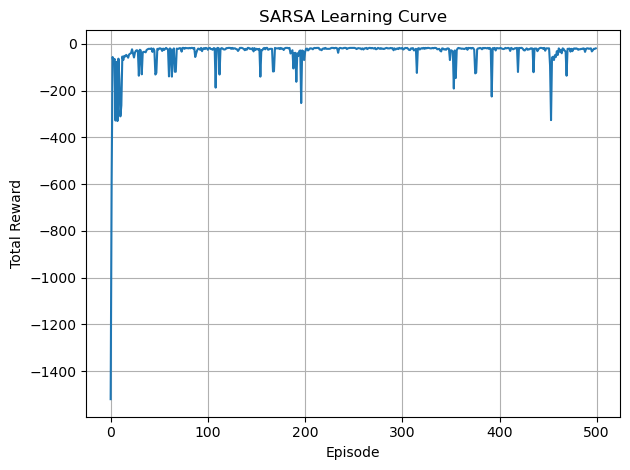

In [10]:
plt.plot(episode_reward)
plt.xlabel("Episode")
plt.ylabel("Total Reward")
plt.grid(True)
plt.title("SARSA Learning Curve")
plt.tight_layout()
plt.savefig("./images/SARSA_Learning_Curve.jpg")
plt.show()